In [37]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# collecting data

In [52]:
base_dir = Path.cwd().resolve().parent
data = base_dir / "data"
raw = data / "raw"
output = base_dir / "outputs"

df_train = pd.read_csv(raw / "train.csv")
df_test = pd.read_csv(raw / "test.csv")

print(df_train.columns)
print(df_test.columns)

Index(['id', 'person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_default_on_file',
       'cb_person_cred_hist_length', 'loan_status'],
      dtype='str')
Index(['id', 'person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_default_on_file',
       'cb_person_cred_hist_length'],
      dtype='str')


# inspecting

In [39]:
print(df_train.head(5))

   id  person_age  person_income person_home_ownership  person_emp_length  \
0   0          37          35000                  RENT                0.0   
1   1          22          56000                   OWN                6.0   
2   2          29          28800                   OWN                8.0   
3   3          30          70000                  RENT               14.0   
4   4          22          60000                  RENT                2.0   

  loan_intent loan_grade  loan_amnt  loan_int_rate  loan_percent_income  \
0   EDUCATION          B       6000          11.49                 0.17   
1     MEDICAL          C       4000          13.35                 0.07   
2    PERSONAL          A       6000           8.90                 0.21   
3     VENTURE          B      12000          11.11                 0.17   
4     MEDICAL          A       6000           6.92                 0.10   

  cb_person_default_on_file  cb_person_cred_hist_length  loan_status  
0              

In [40]:
print(df_train.dtypes)

id                              int64
person_age                      int64
person_income                   int64
person_home_ownership             str
person_emp_length             float64
loan_intent                       str
loan_grade                        str
loan_amnt                       int64
loan_int_rate                 float64
loan_percent_income           float64
cb_person_default_on_file         str
cb_person_cred_hist_length      int64
loan_status                     int64
dtype: object


In [35]:
print(df_train.isnull().sum())
print(df_train['loan_status'].value_counts(normalize=True) * 100)

person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
loan_status                   0
dtype: int64
loan_status
0    85.761787
1    14.238213
Name: proportion, dtype: float64


In [45]:
print("person_home_ownership type: " , df_train['person_home_ownership'].unique())
print("loan_intent type: " , df_train['loan_intent'].unique())
print("loan_grade type: " , df_train['loan_grade'].unique())
print("cb_person_default_on_file type: " , df_train['cb_person_default_on_file'].unique())

person_home_ownership type:  <StringArray>
['RENT', 'OWN', 'MORTGAGE', 'OTHER']
Length: 4, dtype: str
loan_intent type:  <StringArray>
[        'EDUCATION',           'MEDICAL',          'PERSONAL',
           'VENTURE', 'DEBTCONSOLIDATION',   'HOMEIMPROVEMENT']
Length: 6, dtype: str
loan_grade type:  <StringArray>
['B', 'C', 'A', 'D', 'E', 'F', 'G']
Length: 7, dtype: str
cb_person_default_on_file type:  <StringArray>
['N', 'Y']
Length: 2, dtype: str


# EDA

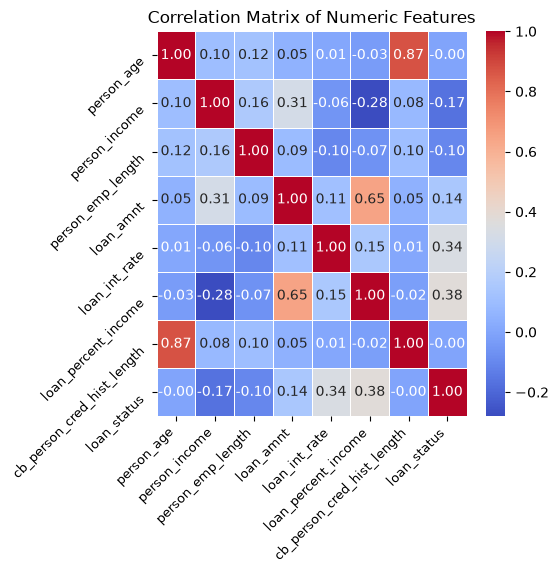

In [61]:
# drop unnecessary ID column
if 'id' in df_train.columns : df_train.drop(['id'], axis=1, inplace=True)

plt.figure(figsize=(5, 5))
numeric_cols = df_train.select_dtypes(include=['int64', 'Float64']).columns
correlation = df_train[numeric_cols].corr()
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.yticks(rotation=45, va='top', fontsize=9)
plt.xticks(rotation=45,ha='right', fontsize=9)

plt.title("Correlation Matrix of Numeric Features")
plt.savefig(fname= output / "correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

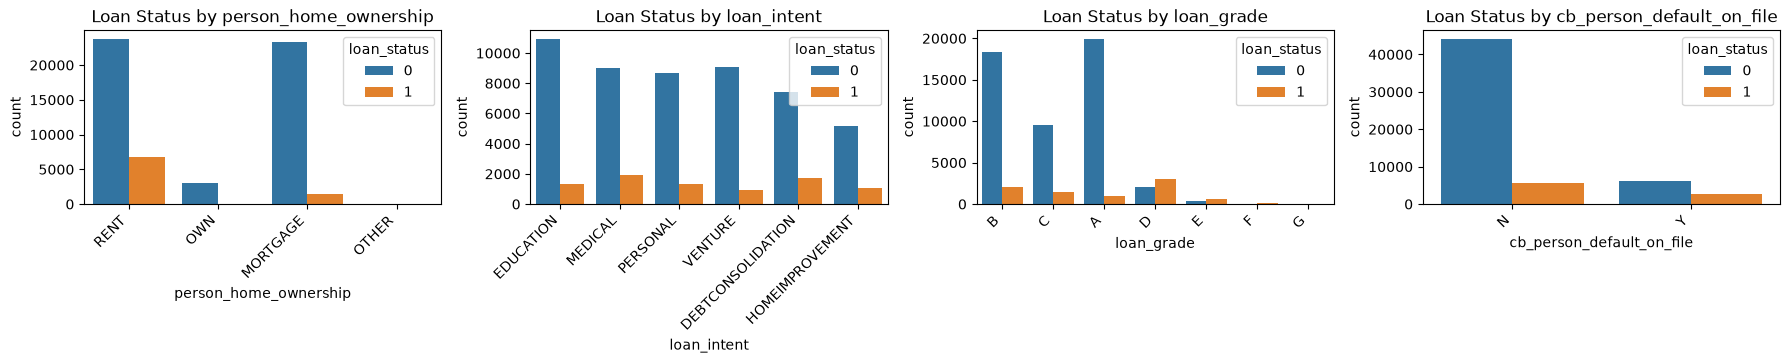

In [79]:
categorical_cols = df_train.select_dtypes(include=['str']).columns
index = 1
plt.figure(figsize=(18,36))
for col in categorical_cols:
    plt.subplot(11,4, index)
    sns.countplot(data=df_train,x=col, hue='loan_status')
    plt.title(f"Loan Status by {col}")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    index+=1
plt.savefig(output / f"categorical.png", dpi=300, bbox_inches='tight')
plt.show()
    